# River Discharge Data

This notebook loads the river discharge data (nodes and streams), which will later be compared with the water quality data.

In [5]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
from pathlib import Path
import sys

# Setup paths (Assuming execution from within SIS_Analysis_WSL/notebooks)
sys.path.append(str(Path.cwd().parent / 'scripts'))
from paths import ProjectPaths
from mapping_config import MappingConfig

In [6]:
# Define paths to the shapefiles
river_nodes_path = ProjectPaths.BOUNDARIES_DIR / "river_lines_SIS" / "setonaikai_river_nodes.shp"
river_stream_path = ProjectPaths.BOUNDARIES_DIR / "river_lines_SIS" / "setonaikai_river_stream.shp"
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"

print("Loading geographic and river network data...")

river_nodes = gpd.read_file(river_nodes_path)
river_streams = gpd.read_file(river_stream_path)
sis_land_boundary = gpd.read_file(land_boundary_path)

Loading geographic and river network data...


In [7]:
# Inspect the loaded datasets
display(river_nodes.head())
display(river_streams.head())

,W05_001,W05_011,W05_000,layer,path,geometry
0,880807,695,t-3600001,W05-06_36-g_RiverNode,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,POINT (133.673 33.876)
1,880807,370,t-3600002,W05-06_36-g_RiverNode,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,POINT (133.678 33.994)
2,880807,689,t-3600003,W05-06_36-g_RiverNode,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,POINT (133.683 33.905)
3,880807,385,t-3600004,W05-06_36-g_RiverNode,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,POINT (133.684 33.999)
4,880807,653,t-3600005,W05-06_36-g_RiverNode,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,POINT (133.684 33.875)


,W05_001,W05_002,W05_003,W05_004,W05_005,W05_006,W05_007,W05_008,W05_009,W05_010,layer,path,geometry
0,360007,3600070000,0,名称不明,3,1,#t-3603836,#t-3603826,#t-3603836,#t-3603826,W05-06_36-g_Stream,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,"LINESTRING (459269.588 3758416.184, 459258.404..."
1,880807,8808070000,0,名称不明,3,1,#t-3603243,#t-3603249,#t-3603243,#t-3603249,W05-06_36-g_Stream,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,"LINESTRING (450067.514 3764218.666, 450069.488..."
2,880807,8808070000,0,名称不明,3,1,#t-3603097,#t-3603120,#t-3603097,#t-3603120,W05-06_36-g_Stream,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,"LINESTRING (447851.955 3765856.213, 447858.99 ..."
3,880807,8808070000,0,名称不明,2,1,#t-3603086,#t-3603106,#t-3603086,#t-3603106,W05-06_36-g_Stream,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,"LINESTRING (447652.901 3766304.003, 447656.7 3..."
4,360007,3600070000,0,名称不明,3,1,#t-3603495,#t-3603505,#t-3603495,#t-3603505,W05-06_36-g_Stream,C:/Users/reyha/Documents/SIS_Analysis_Windows/...,"LINESTRING (453957.614 3759034.065, 453975.241..."


Generating map...


ValueError: Axis limits cannot be NaN or Inf

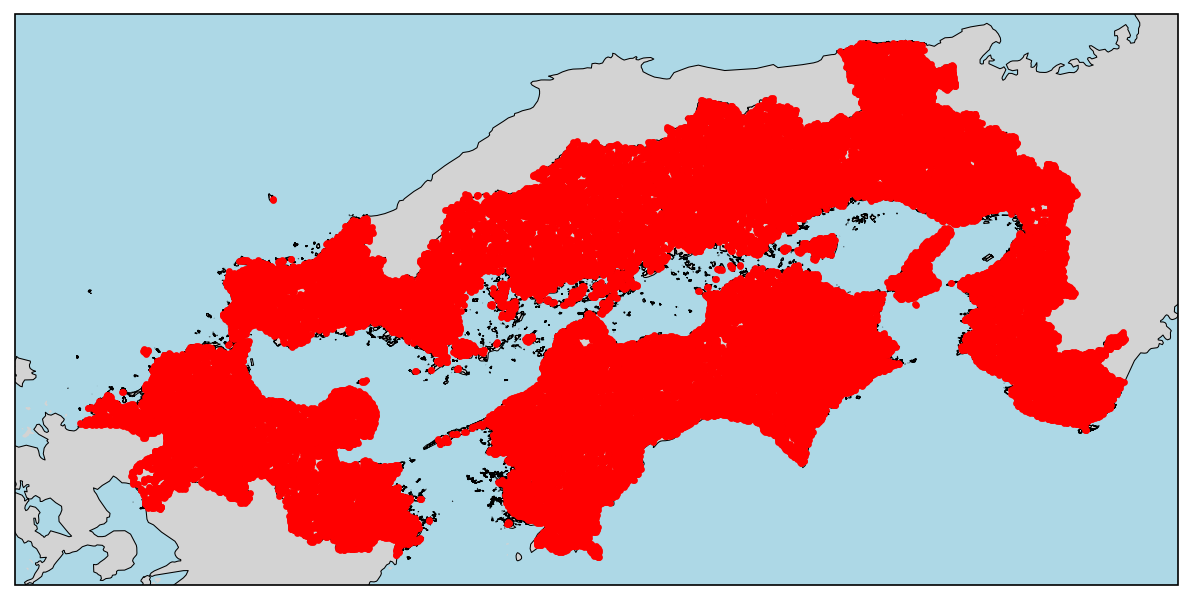

In [9]:
# Enforce WGS84 for plate carree projection compatibility
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

print("Generating map...")
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# Ocean background 
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Plot standard Cartopy Land and Coastlines underneath to fill the gaps
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# Plot high-resolution land masses on top
sis_land_boundary.plot(
    ax=ax,
    facecolor=MappingConfig.COLOR_LAND,
    edgecolor=MappingConfig.COLOR_LAND_EDGE,
    linewidth=MappingConfig.LINEWIDTH_LAND,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_LAND
)

# Plot streams (blue lines) underneath the nodes
river_streams.plot(
    ax=ax, color='blue', linewidth=0.5, 
    transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED
)

# Plot nodes (red dots) on top of the streams
river_nodes.plot(
    ax=ax, color='red', markersize=5, 
    transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS
)

# Map Extent
bounds = river_streams.total_bounds
ax.set_extent([
    bounds[0] - 0.2,
    bounds[2] + 0.2,
    bounds[1] - 0.2,
    bounds[3] + 0.2
], crs=ccrs.PlateCarree())

# Gridlines
gl = ax.gridlines(
    draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
    color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
    linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES
)
gl.top_labels = False
gl.right_labels = False

# Add customized legend
legend_elements = [
    Line2D([0], [0], color='blue', lw=1, label='River Streams'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=5, label='River Nodes')
]
ax.legend(handles=legend_elements, loc='best')

plt.title('Seto Inland Sea River Discharge Nodes and Streams')
plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)
plt.show()